In [1]:
import numpy as np
import requests
import json
from scipy.interpolate import make_interp_spline
from scipy.interpolate import PchipInterpolator
from splinecloud_scipy import ( 
    load_spline, 
    load_spline_surface, 
    ParametricBivariateSpline, 
    ParametricTrivariateSpline,
    LoftedSplineVolume,
    InterpolatedSplineVolume
)
import matplotlib.pyplot as plt
# %matplotlib widget
%matplotlib notebook

## Load surfaces from SplineCloud

In [2]:
cla_norm_surfaces = {
    "AR=6": "srf_8E0ui4ABe5st",
    "AR=8": "srf_IA936WqOzbyy",
    "AR=10": "srf_8ee5vCk1WlMM",
    "AR=12": "srf_cPn2USXrFGJ8"
}

In [3]:
AR_values = [int(key.split("=")[1]) for key in cla_norm_surfaces]
surf_uids = list(cla_norm_surfaces.values())

## LoftedSplineVolume model

In [4]:
volume_spline_model = LoftedSplineVolume(surf_uids, AR_values)

### Test evaluation

In [5]:
## single point evaluation, no extrapolation
volume_spline_model.eval(0.3, 0.5, 11, extrapolate=False)

0.7622983961624747

In [6]:
## single point evaluation, with extrapolation
volume_spline_model.eval(1.0, 0.5, 13, extrapolate=True)

0.15396645562428893

In [7]:
## array-like x3 variable evaluation, no extrapolation
volume_spline_model.eval(0.3, 0.5, np.linspace(6, 13), extrapolate=False)

array([[[0.30773321, 0.33026795, 0.35201106, 0.37298371, 0.39320707,
         0.41270227, 0.43149041, 0.44959255, 0.46702972, 0.48382289,
         0.49999301, 0.51556099, 0.53054767, 0.54497389, 0.55886042,
         0.57222801, 0.58509737, 0.59748918, 0.60942406, 0.62092264,
         0.63200549, 0.64269318, 0.65300622, 0.66296515, 0.67259045,
         0.68190259, 0.69092205, 0.69966926, 0.70816468, 0.71642874,
         0.72448187, 0.73234449, 0.74003702, 0.7475799 , 0.75499355,
         0.7622984 , 0.76951487, 0.77666342, 0.7837645 , 0.79083855,
         0.79790605, 0.80498747, 0.81210331, 0.81214781, 0.8121923 ,
         0.81223679, 0.81228127, 0.81232574, 0.81237021, 0.81241466]]])

In [8]:
## array-like x3 variable evaluation, with extrapolation
volume_spline_model.eval(0.3, 0.5, np.linspace(4,15), extrapolate=True)

array([[[-0.10276064, -0.04692326,  0.00625733,  0.05686246,
          0.10497386,  0.15067354,  0.19404375,  0.23516689,
          0.27412539,  0.31100173,  0.34587829,  0.37883734,
          0.40996102,  0.43933125,  0.46702972,  0.49313791,
          0.51773704,  0.54090809,  0.56273178,  0.58328861,
          0.60265887,  0.62092264,  0.63815981,  0.65445013,
          0.66987321,  0.68450855,  0.69843555,  0.71173356,
          0.72448187,  0.73675974,  0.74864643,  0.76022121,
          0.77156335,  0.78275219,  0.79386709,  0.80498747,
          0.81619284,  0.82756279,  0.83917697,  0.85111516,
          0.86345724,  0.87628319,  0.88967313,  0.90370729,
          0.91846604,  0.93402989,  0.95047949,  0.96789561,
          0.98635918,  1.00595124]]])

In [9]:
etas = np.linspace(0.0, 1.0, 11)
taper_ratios = np.linspace(0.2, 1.0, 9)
aspect_ratios = np.linspace(6, 15, 7)

print("etas:", etas)
print("taper_ratios:", taper_ratios)
print("aspect_ratios:", aspect_ratios)

etas: [0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
taper_ratios: [0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
aspect_ratios: [ 6.   7.5  9.  10.5 12.  13.5 15. ]


In [10]:
## array-like x1, x2, x3 variable evaluation, with extrapolation
volume_spline_model.eval(etas, taper_ratios, aspect_ratios, extrapolate=True)

array([[[0.32588377, 0.45241718, 0.55058486, 0.62768182, 0.69100304,
         0.74784353, 0.80549828],
        [0.28334708, 0.4401861 , 0.55140798, 0.63376305, 0.70254211,
         0.7726659 , 0.85762638],
        [0.27074798, 0.44525798, 0.56539602, 0.65157828, 0.72329784,
         0.799889  , 0.90000317],
        [0.2808952 , 0.46565299, 0.59155175, 0.68020509, 0.75291702,
         0.83101912, 0.93588243],
        [0.31123079, 0.50062754, 0.62937473, 0.71909158, 0.79134485,
         0.8677437 , 0.97008813],
        [0.36063143, 0.54902676, 0.67747266, 0.76674018, 0.83756172,
         0.91067508, 1.00699719],
        [0.41570719, 0.59966557, 0.72589622, 0.8138317 , 0.88293648,
         0.95270559, 1.04280419],
        [0.45656085, 0.63767239, 0.76226948, 0.8491169 , 0.91699769,
         0.98471624, 1.07112988],
        [0.47164469, 0.654072  , 0.77903737, 0.86568301, 0.93315115,
         1.00058398, 1.08712374]],

       [[0.34892201, 0.48342157, 0.58730511, 0.66844135, 0.73452664,
  

### Test interpolation and extrapolation

In [11]:
cla_norm_AR6_surf = load_spline_surface(cla_norm_surfaces["AR=6"])
cla_norm_AR8_surf = load_spline_surface(cla_norm_surfaces["AR=8"])
cla_norm_AR10_surf = load_spline_surface(cla_norm_surfaces["AR=10"])
cla_norm_AR12_surf = load_spline_surface(cla_norm_surfaces["AR=12"])

In [12]:
etas = np.linspace(0.0, 1.0, 100)
TR = 0.2

In [13]:
cla_norm_surf_AR6_vals = np.array([cla_norm_AR6_surf.eval(eta, TR, extrapolate=True) for eta in etas])
cla_norm_surf_AR8_vals = np.array([cla_norm_AR8_surf.eval(eta, TR, extrapolate=True) for eta in etas])
cla_norm_surf_AR10_vals = np.array([cla_norm_AR10_surf.eval(eta, TR, extrapolate=True) for eta in etas])
cla_norm_surf_AR12_vals = np.array([cla_norm_AR12_surf.eval(eta, TR, extrapolate=True) for eta in etas])

In [14]:
cla_norm_volume_model_AR7_vals = [volume_spline_model.eval(eta, TR, 7, extrapolate=True) for eta in etas]
cla_norm_volume_model_AR9_vals = [volume_spline_model.eval(eta, TR, 9, extrapolate=True) for eta in etas]
cla_norm_volume_model_AR11_vals = [volume_spline_model.eval(eta, TR, 11, extrapolate=True) for eta in etas]
cla_norm_volume_model_AR13_vals = [volume_spline_model.eval(eta, TR, 13, extrapolate=True) for eta in etas]

<IPython.core.display.Javascript object>


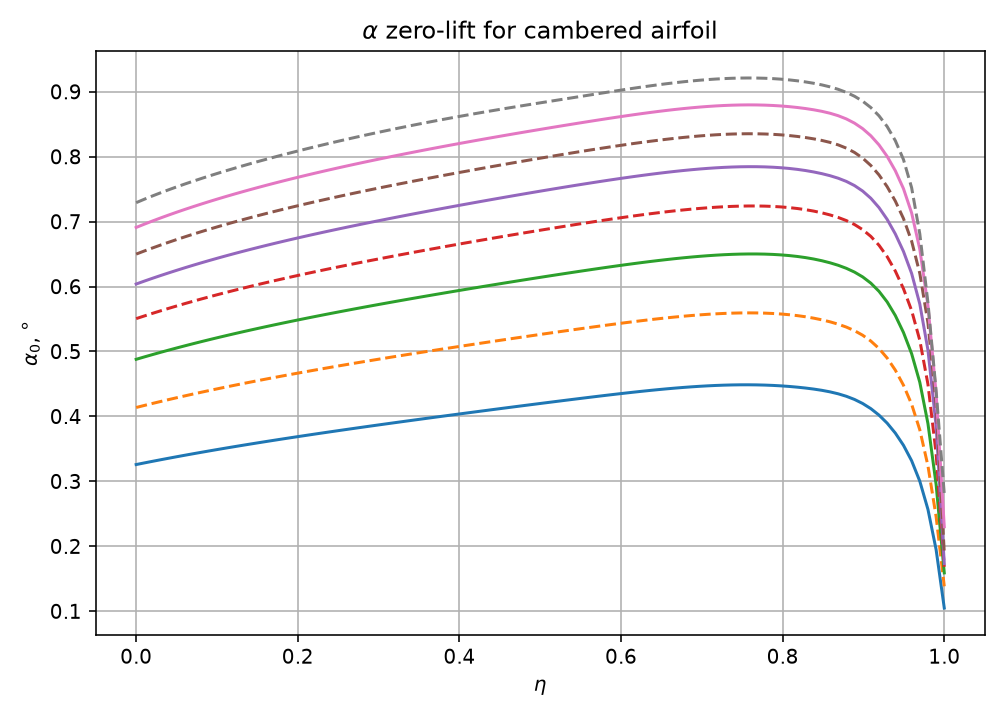

In [15]:
# Plot cla_norm 
fig = plt.figure(figsize=(7, 5))

ax = fig.add_subplot(111)
ax.set_title(r"$\alpha$ zero-lift for cambered airfoil")
ax.set_xlabel(r"$\eta$")
ax.set_ylabel(r"$\alpha_0$, °")
ax.plot(etas, cla_norm_surf_AR6_vals)
ax.plot(etas, cla_norm_volume_model_AR7_vals, "--")
ax.plot(etas, cla_norm_surf_AR8_vals)
ax.plot(etas, cla_norm_volume_model_AR9_vals, "--")
ax.plot(etas, cla_norm_surf_AR10_vals)
ax.plot(etas, cla_norm_volume_model_AR11_vals, "--")
ax.plot(etas, cla_norm_surf_AR12_vals)
ax.plot(etas, cla_norm_volume_model_AR13_vals, "--")

plt.grid()
plt.tight_layout()
plt.show()

## InterpolatedSplineVolume model

In [16]:
volume_spline_model = InterpolatedSplineVolume(surf_uids, AR_values)

### Test evaluation

In [17]:
## single point evaluation, no extrapolation
volume_spline_model.eval(0.3, 0.5, 11, extrapolate=False)

0.7652967787811357

In [18]:
## single point evaluation, with extrapolation
volume_spline_model.eval(1.0, 0.5, 13, extrapolate=True)

0.15218304635060256

In [19]:
## array-like x3 variable evaluation, no extrapolation
volume_spline_model.eval(0.3, 0.5, np.linspace(6, 13), extrapolate=False)

array([[[0.30773321, 0.32910898, 0.35006904, 0.37058508, 0.3906288 ,
         0.41017188, 0.42918603, 0.44764292, 0.46551426, 0.48277174,
         0.49938705, 0.51533188, 0.53057792, 0.54509687, 0.55886042,
         0.57198998, 0.58464219, 0.59684157, 0.60861266, 0.61998   ,
         0.6309681 , 0.64160152, 0.65190477, 0.66190239, 0.67161892,
         0.68107888, 0.6903068 , 0.69932723, 0.70816468, 0.71684308,
         0.72536407, 0.73371875, 0.74189825, 0.74989368, 0.75769615,
         0.76529678, 0.77268668, 0.77985698, 0.78679877, 0.79350319,
         0.79996134, 0.80616434, 0.81210331, 0.81210331, 0.81210331,
         0.81210331, 0.81210331, 0.81210331, 0.81210331, 0.81210331]]])

In [20]:
## array-like x3 variable evaluation, with extrapolation
volume_spline_model.eval(0.3, 0.5, np.linspace(4,15), extrapolate=True)

array([[[-0.0193251 ,  0.01873342,  0.05670407,  0.094477  ,
          0.13194238,  0.16899035,  0.20551108,  0.2413947 ,
          0.27653138,  0.31081127,  0.34412452,  0.37636129,
          0.40741174,  0.43716601,  0.46551426,  0.49234665,
          0.51755332,  0.54102444,  0.56266186,  0.58286302,
          0.60193734,  0.61998   ,  0.6370862 ,  0.65335114,
          0.66887002,  0.68373803,  0.69805037,  0.7119027 ,
          0.72536407,  0.73841477,  0.75102034,  0.76314628,
          0.77475814,  0.78582141,  0.79630164,  0.80616434,
          0.81537504,  0.82389925,  0.8317025 ,  0.83875031,
          0.8450082 ,  0.85044171,  0.85501633,  0.85869761,
          0.86145107,  0.86324221,  0.86403658,  0.86379968,
          0.86249705,  0.8600942 ]]])

In [21]:
## array-like x1, x2, x3 variable evaluation, with extrapolation
volume_spline_model.eval(etas, taper_ratios, aspect_ratios, extrapolate=True)

array([[[0.32588377, 0.45227936, 0.55036246, ..., 0.69100304,
         0.73542925, 0.75617433],
        [0.28334708, 0.43966337, 0.55085543, ..., 0.70254211,
         0.74882666, 0.76738294],
        [0.27074798, 0.44474358, 0.56457827, ..., 0.72329784,
         0.76934997, 0.78358503],
        ...,
        [0.41570719, 0.59943777, 0.72503585, ..., 0.88293648,
         0.92068974, 0.91741205],
        [0.45656085, 0.63746654, 0.76144807, ..., 0.91699769,
         0.95365118, 0.94925555],
        [0.47164469, 0.65387424, 0.77819388, ..., 0.93315115,
         0.96890845, 0.9628384 ]],

       [[0.32839173, 0.45570618, 0.55448214, ..., 0.69605635,
         0.74073176, 0.76151885],
        [0.28519741, 0.44251052, 0.55437786, ..., 0.70693058,
         0.75344525, 0.77203444],
        [0.27225391, 0.4471724 , 0.56761412, ..., 0.72709128,
         0.77333356, 0.78757238],
        ...,
        [0.41645423, 0.60049154, 0.72627904, ..., 0.88438508,
         0.92216449, 0.91883125],
        [0.4

### Test interpolation and extrapolation

In [22]:
cla_norm_volume_model_AR7_vals = [volume_spline_model.eval(eta, TR, 7, extrapolate=True) for eta in etas]
cla_norm_volume_model_AR9_vals = [volume_spline_model.eval(eta, TR, 9, extrapolate=True) for eta in etas]
cla_norm_volume_model_AR11_vals = [volume_spline_model.eval(eta, TR, 11, extrapolate=True) for eta in etas]
cla_norm_volume_model_AR13_vals = [volume_spline_model.eval(eta, TR, 13, extrapolate=True) for eta in etas]

<IPython.core.display.Javascript object>


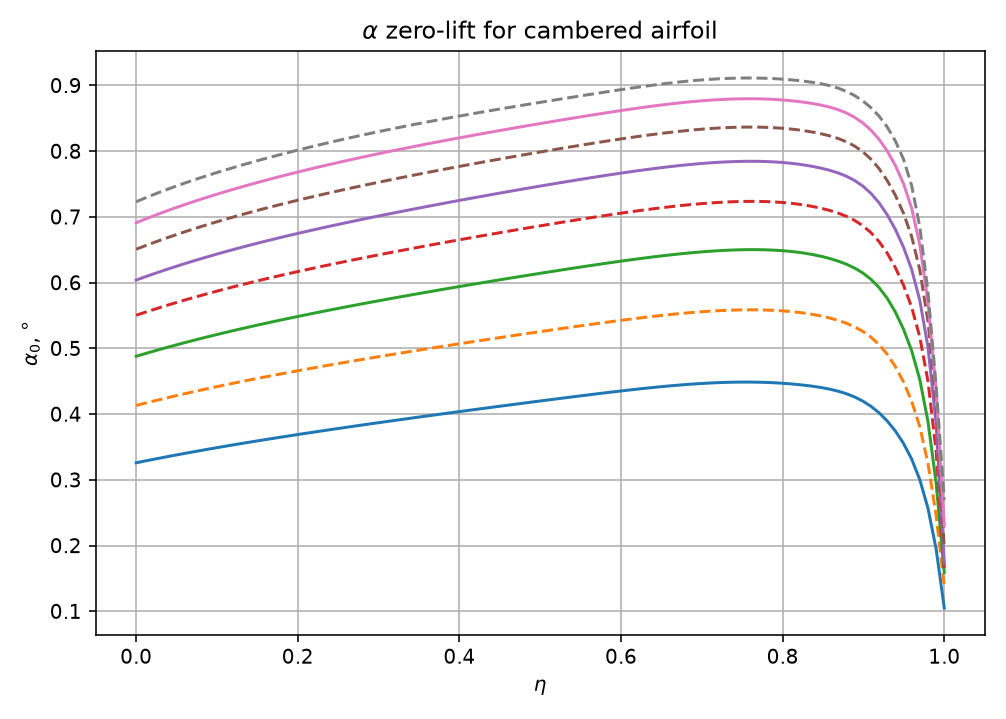

In [23]:
# Plot cla_norm 
fig = plt.figure(figsize=(7, 5))

ax = fig.add_subplot(111)
ax.set_title(r"$\alpha$ zero-lift for cambered airfoil")
ax.set_xlabel(r"$\eta$")
ax.set_ylabel(r"$\alpha_0$, °")
ax.plot(etas, cla_norm_surf_AR6_vals)
ax.plot(etas, cla_norm_volume_model_AR7_vals, "--")
ax.plot(etas, cla_norm_surf_AR8_vals)
ax.plot(etas, cla_norm_volume_model_AR9_vals, "--")
ax.plot(etas, cla_norm_surf_AR10_vals)
ax.plot(etas, cla_norm_volume_model_AR11_vals, "--")
ax.plot(etas, cla_norm_surf_AR12_vals)
ax.plot(etas, cla_norm_volume_model_AR13_vals, "--")

plt.grid()
plt.tight_layout()
plt.show()